# Exercise 3

Student name: Divya Srivastava

Student id:2623454

# Fashion mnist classification, model selection and confusion matrix interpretation
Target of the exercise is to create a classifier for Fashion MNIST data set (see https://github.com/zalandoresearch/fashion-mnist). Use Logistic Regression, Random Forest, and a support vector classifier as your model candidates. Search for hyperparameter values for the models that have those. The search can be limited to save time and computing resources. Use the process (split into training, validation, test, etc) we have discussed (you might also want to use k-fold validation). Present your solution in as clear and systematic way as possible. Identify the best model of the three and present the results from that.

Discuss findings you can make based on the confusion matrix. Compare your results against state of the art results.

Return the assignment as Jupyter notebook.

Note1: Fashion MNIST can be loaded in a way quite similar to loading standard MNIST, check documentation for the correct function name (no need to download zip files from github or similar). 

Note2: Please use the markup cell feature of jupyter notebooks to explain steps you take in your solution.

Assignment type: Personal assignment
Publishing date: 05.11.2026 15.30
Deadline: 19.11.2026 16.00 (ehdoton palautusaika)
Visibility of assignment answers: Answers are visible only for teachers
Yleinen linkki: https://oma.metropolia.fi/delegate/object-redirect/workspace_assignment?taskId=312284445&workspace.id=340052473

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import sklearn.datasets
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.svm import SVR
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import StratifiedKFold
from sklearn.base import clone

The code fetches the FMNIST dataset using fetch_openml from sklearn.datasets 

In [4]:
from sklearn.datasets import fetch_openml
X, y = fetch_openml("Fashion-MNIST", version = 1,return_X_y=True, as_frame=False,  parser="liac-arff")
print(type(X))
print(type(y))


<class 'numpy.ndarray'>
<class 'numpy.ndarray'>


1) 'data' key: an array with one row per instance and one column per feature

2) 'target' key: an array with the labels

## Step 1: Explore and Visualise the Dataset
Determine the number of images, features, and labels in the dataset. Then, select an image from the dataset and display it using imshow().

Number of images and features: (70000, 784)
Number of labels: (70000,)


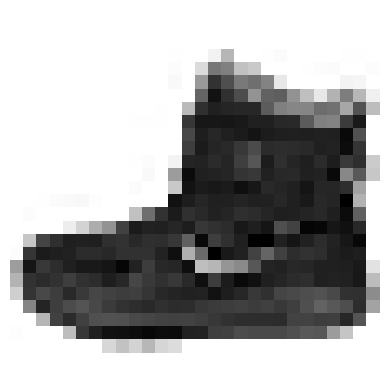

In [5]:

print("Number of images and features:", X.shape)
print("Number of labels:", y.shape)
#Display one of the images from the fmnist dataset
sample_image = X[0]
#reshape sample_image in 2D array
sample_image_2D = sample_image.reshape(28, 28)
#Display
plt.imshow(sample_image_2D, cmap="binary")
plt.axis("off")
plt.show()


## Step 2: standardise the data

Use sklearn StandardScaler to standardise the data. 

In [6]:
scaler = StandardScaler().fit(X)
scaled_x = scaler.transform(X)

## Step 3: Divide data into training, validation and test sets

First divide the available data into development and test sets. Use 20% for the test set. 

Next, divide the development set further into training and validation sets. Use 30% of the development set for the validation.

In [7]:
# split data into training and validation (=dev) set and test set
dev_x, test_x, dev_y, test_y = train_test_split(scaled_x, y, test_size=0.2, random_state = 42)
# and next split the dev set into training and validation sets
train_x, val_x, train_y, val_y = train_test_split(dev_x, dev_y, test_size=0.3, random_state=42)
print("Devloping Set: ", dev_x.shape, dev_y.shape, "Testing Set: ", test_x.shape, test_y.shape)
print("Traing set: ", train_x.shape, train_y.shape, "Validation Set:",  val_x.shape, val_y.shape)

Devloping Set:  (56000, 784) (56000,) Testing Set:  (14000, 784) (14000,)
Traing set:  (39200, 784) (39200,) Validation Set: (16800, 784) (16800,)


## Step 4:  Logistic Regression + hyperparameter search on training data

In [8]:
#LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report
clf = LogisticRegression(solver='saga', tol=0.1).fit(train_x, train_y)
print("training accuracy", clf.score(train_x, train_y))
print("validation accuracy", clf.score(val_x, val_y))


training accuracy 0.8454081632653061
validation accuracy 0.8401785714285714


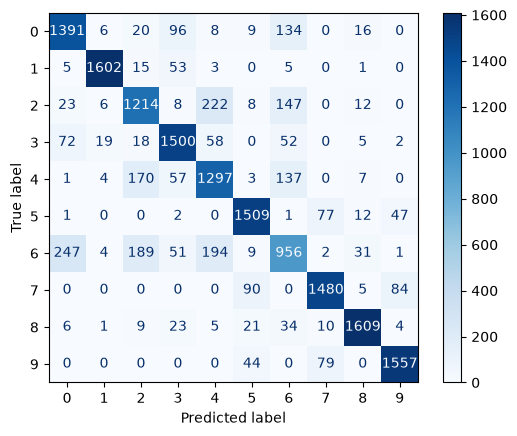

In [9]:
#Display Confusion Matrix
disp = ConfusionMatrixDisplay.from_estimator(clf,val_x, val_y, display_labels=clf.classes_, cmap=plt.cm.Blues)

In [8]:
#hyperparameter search space
parameters = {"C": [0.1, 1, 10], "solver": ["saga", "lbfgs"], "tol":[0.1, 0.01]}
clf = GridSearchCV(LogisticRegression(max_iter=1000), parameters, cv=5, scoring='f1_weighted', n_jobs=8)
clf.fit(train_x, train_y)
print(clf.best_params_)
print(classification_report(val_y, clf.predict(val_x)))


{'C': 10, 'solver': 'saga', 'tol': 0.01}
              precision    recall  f1-score   support

           0       0.81      0.83      0.82      1680
           1       0.98      0.96      0.97      1684
           2       0.75      0.76      0.75      1640
           3       0.86      0.87      0.87      1726
           4       0.75      0.79      0.77      1676
           5       0.93      0.93      0.93      1649
           6       0.67      0.60      0.63      1684
           7       0.92      0.93      0.92      1659
           8       0.96      0.94      0.95      1722
           9       0.94      0.94      0.94      1680

    accuracy                           0.86     16800
   macro avg       0.85      0.86      0.85     16800
weighted avg       0.86      0.86      0.86     16800



## Step 5:  RandomForest hyperparameter search on training data

In [16]:

parameters = {'n_estimators': [10, 100], "max_depth":[100,10, None]}
clf_rf = GridSearchCV(RandomForestClassifier(), parameters, cv=5, scoring='f1_weighted', n_jobs=8)
clf_rf.fit(train_x, train_y)
print(clf_rf.best_params_)
print(classification_report(val_y, clf_rf.predict(val_x)))


{'max_depth': None, 'n_estimators': 100}
              precision    recall  f1-score   support

           0       0.81      0.86      0.83      1680
           1       0.99      0.96      0.98      1684
           2       0.77      0.82      0.79      1640
           3       0.88      0.91      0.89      1726
           4       0.77      0.84      0.80      1676
           5       0.97      0.95      0.96      1649
           6       0.74      0.57      0.64      1684
           7       0.93      0.94      0.94      1659
           8       0.95      0.97      0.96      1722
           9       0.95      0.96      0.95      1680

    accuracy                           0.88     16800
   macro avg       0.88      0.88      0.88     16800
weighted avg       0.88      0.88      0.88     16800



## Step 6:  SVC hyperparameter search on training data

In [10]:
import time 
parameters = {'kernel':['linear', 'poly', 'rbf'], 'C':[2, 10], 'gamma':[0.1,  0.5]}
start_time = time.perf_counter()
#parameters = {'kernel':['linear', 'poly', 'rbf'], 'C':[2, 10, 50], 'gamma':[0.1,  0.5]}
clf_SVC = GridSearchCV(SVC(), parameters, cv=5, scoring='f1_weighted', n_jobs=8)
clf_SVC.fit(train_x, train_y)
print(clf_SVC.best_params_)
print(classification_report(val_y, clf_rf.predict(val_x)))
end_time = time.perf_counter()

{'C': 2, 'gamma': 0.1, 'kernel': 'poly'}
              precision    recall  f1-score   support

           0       0.81      0.87      0.84      1680
           1       1.00      0.96      0.98      1684
           2       0.78      0.82      0.80      1640
           3       0.88      0.91      0.90      1726
           4       0.77      0.83      0.80      1676
           5       0.97      0.95      0.96      1649
           6       0.74      0.59      0.66      1684
           7       0.93      0.94      0.94      1659
           8       0.95      0.97      0.96      1722
           9       0.95      0.95      0.95      1680

    accuracy                           0.88     16800
   macro avg       0.88      0.88      0.88     16800
weighted avg       0.88      0.88      0.88     16800



## Step 7: Final Model Selection, Training, and Evaluation

Both SVC and Random Forest achieved the same classification accuracy of 88%. However, Random Forest required significantly less training time than SVC, making it more computationally efficient. Therefore, Random Forest was selected as the best model among the three. The selected model will be retrained using the combined training and validation datasets, and its final performance will be evaluated on the test dataset

# Random Forest Classifier

In [19]:
CLF_RF = RandomForestClassifier( **clf_rf.best_params_,
    random_state=42,
    n_jobs=8)
CLF_RF.fit(dev_x, dev_y)
print("training accuracy", CLF_RF.score(dev_x, dev_y))
print("test accuracy", CLF_RF.score(test_x, test_y))

training accuracy 1.0
test accuracy 0.8825714285714286


RandomForestClassifier() model trained on (training and validation data = dev) achieved 100% training accuracy, however, a test accuracy of 88.26%. The difference of approximately 11.74 % indicates that the model fits the training data considerably better than unseen data, suggesting some overfitting.

### Display Confusion Matrix

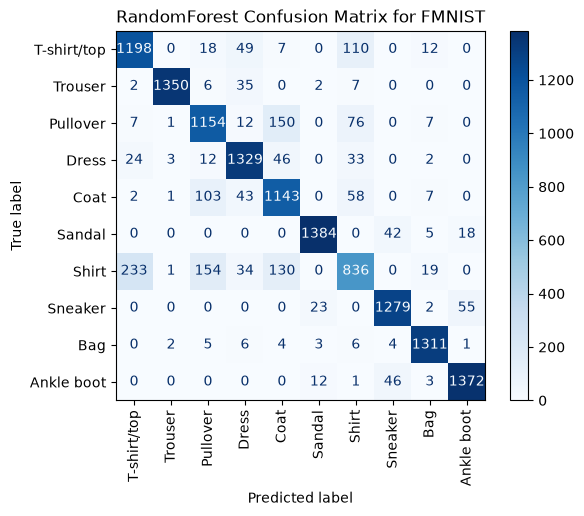

In [24]:
class_label = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress',
    'Coat', 'Sandal', 'Shirt', 'Sneaker',
    'Bag', 'Ankle boot']
disp = ConfusionMatrixDisplay.from_estimator(CLF_RF,test_x, test_y, display_labels=class_label, xticks_rotation=90, cmap=plt.cm.Blues)
plt.title("RandomForest Confusion Matrix for FMNIST")
plt.show()

RandomForest model classified FMNIST data with an overall test accuracy of 88.26%. Misclassifications occur mainly among visually similar clothing categories, particularly shirts, T-shirts, pullovers, and coats. 


### Since Random Forest shows some signs of overfitting, I will also train and evaluate an SVC classifier to investigate whether it provides better generalization performance.

# Support Vector Classifier (SVC)

In [10]:
CLF_SVC = SVC(C= 2, gamma = 0.1, kernel ='poly')
CLF_SVC.fit(dev_x, dev_y)
print("training accuracy", CLF_SVC.score(dev_x, dev_y))
print("test accuracy", CLF_SVC.score(test_x, test_y))

training accuracy 1.0
test accuracy 0.9011428571428571


Both SVC and Random Forest achieved 100% training accuracy, suggesting possible overfitting, as their test accuracies were lower. In SVC, reducing the regularization parameter `C` increases the strength of regularization, which may help reduce overfitting and improve generalization.

In GridSearchCV, only `C = 2, 10, and 50` were tested. Therefore, smaller values of `C`, such as 0.1, 0.5, or 1, might provide better generalization performance. However, because hyperparameter tuning was computationally expensive and time-consuming, I did not perform additional experiments to verify this possibility.

### Display Confusion Matrix for SVC

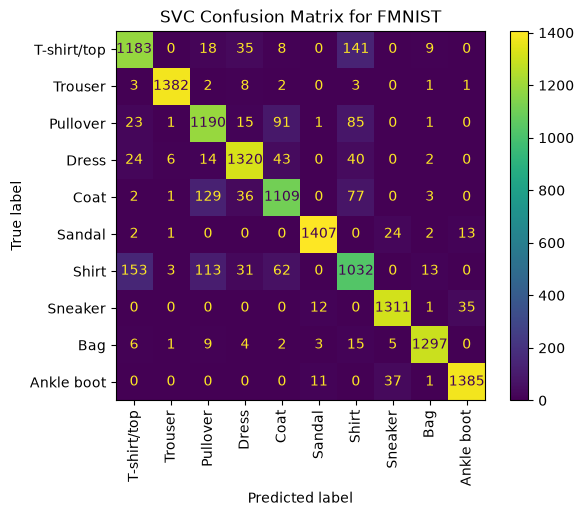

In [15]:
class_label = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress',
    'Coat', 'Sandal', 'Shirt', 'Sneaker',
    'Bag', 'Ankle boot']
disp = ConfusionMatrixDisplay.from_estimator(CLF_SVC,test_x, test_y, display_labels=class_label, xticks_rotation=90, cmap=plt.cm.viridis)
plt.title("SVC Confusion Matrix for FMNIST")
plt.show()

The SVC classifier classified the FMNIST data with an overall test accuracy of 90.11%, slightly more accurately than the Random Forest classifier. Both classifiers performed particularly well on trousers, sandals, sneakers, bags, and ankle boots, while shirts were frequently misclassified as T-shirts (mostly), pullovers, or coats. Pullovers were mostly misclassified as coats and vice versa. T-shirts/tops were mostly misclassified as shirts. Overall, the SVC classifier showed better performance and had fewer misclassifications than the Random Forest classifier.

<div style="border: 2px solid blue; padding: 10px; border-radius: 5px;">
<b>Among the three models studied, SVC demonstrated the best performance.</b>
</div>

### Compare SVC results against state of the art results.
The SVC classifier achieved a test accuracy of 90.11% on the Fashion-MNIST dataset. In comparison, a study published in 2024 ( **Mukhamediev, R.I.**
State-of-the-Art Results with the
Fashion-MNIST Dataset. **Mathematics
2024, 12, 3174.**  **DOI:** https://doi.org/10.3390/math12203174 ) reported a state-of-the-art accuracy of 99.65% using the CNN-3-128 model, consisting of three convolutional layers and data augmentation. Thus, our SVC classifier achieved approximately 9.54 percentage points lower accuracy than the reported CNN model. Nevertheless, SVC demonstrated good classification performance using a traditional machine-learning approach.
    